# TREO on PASTIS — test-set evaluation, predicted masks, and "more images as the season goes on"

Three things:

1. **Sanity check** — reproduce the reported test mIoU for a trained run.
2. **Qualitative** — predicted segmentation masks vs. ground truth.
3. **The experiment** — take the model **trained on 2 images** and feed it *more* images at
   test time. Does the belief keep improving as the season delivers more acquisitions?

### Read this before interpreting anything

The dataset picks frames with `torch.linspace(0, N-1, T)` over the ~43 acquisitions of the
series. That has a consequence which is easy to miss:

> **"Trained on 2 images" does not mean "two early-season images".** At `T=2`, linspace returns
> the **first and last** acquisition — roughly Sept 2018 and Oct 2019, a **13-month gap**.

So the T=2 model was trained on a wide-baseline pair, not on the start of a season. That
matters because TREO conditions its recurrence on Δt, and adding frames changes the Δt
distribution it sees. Two different test protocols follow from this, and they answer
different questions — both are computed below:

| | how "more images" is built | question it answers |
|---|---|---|
| **A — densification** | re-sample with `linspace(0, N-1, k)`; every k spans the whole season | "same season, sampled more finely" — matches how the model was trained |
| **B — streaming prefix** | fix a 12-frame grid, feed the **first k** frames | "the season is unfolding and images arrive one by one" — matches your mental model |

Protocol B is the honest version of "during the season we have more images", but it is
**off-distribution** for this model in a specific way: at k=2 it sees Sep+Oct 2018 (one month
apart), whereas training always paired Sep 2018 with Oct 2019. Expect B to look worse.

**Kernel:** use the venv with the full stack —
`/home/gianfranco/projects/2025/Project_1/nested_mae_BEN/.venv/bin/python`.

In [ ]:
import os, sys, logging, warnings
warnings.filterwarnings("ignore")

REPO = "/home/gianfranco/projects/2025/Project_1/pangaea-bench-old"
if REPO not in sys.path:
    sys.path.insert(0, REPO)
os.chdir(REPO)

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from omegaconf import OmegaConf
from hydra.utils import instantiate

from pangaea.datasets.base import GeoFMDataset
from pangaea.utils.collate_fn import get_collate_fn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
logging.basicConfig(level=logging.WARNING)
LOG = logging.getLogger("nb")

# ---- which trained run to analyse -------------------------------------------------
# Every run dir in the repo root is a full experiment: its configs/config.yaml is
# self-contained, so we rebuild the exact model that was trained.
RUN_DIR = "20260908_233452_31f3e0_treo_seg_upernet_mt_none_pastis_s2_dates"  # the T=2 model
CKPT    = "checkpoint__best.pth"

cfg = OmegaConf.load(os.path.join(RUN_DIR, "configs", "config.yaml"))
TRAIN_T = cfg.dataset.multi_temporal
print(f"run          : {RUN_DIR}")
print(f"trained with : T = {TRAIN_T} images   (finetune={cfg.finetune}, seed={cfg.seed})")
print(f"device       : {DEVICE}")

run          : 20260908_225527_205ef3_treo_seg_upernet_mt_none_pastis_s2_dates
trained with : T = 3 images   (finetune=False, seed=234)
device       : cuda


## 1. Rebuild the trained model

Mirrors `pangaea/run.py`: instantiate the encoder, then the decoder wrapping it, then load the
run's checkpoint. The saved `state_dict` holds encoder **and** decoder weights (the encoder was
frozen, so its tensors equal the pretrained ones — loading them back is a no-op that also
double-checks nothing drifted).

No `torch.distributed` here: we run our own inference loop rather than the DDP evaluator.

In [2]:
def build_model(cfg, run_dir, ckpt_name=CKPT, device=DEVICE):
    encoder = instantiate(cfg.encoder)
    encoder.load_encoder_weights(LOG)                 # pretrained TREO backbone
    model = instantiate(cfg.decoder, encoder=encoder) # SegMTUPerNet(encoder=...)

    sd = torch.load(os.path.join(run_dir, ckpt_name), map_location="cpu",
                    weights_only=False)
    missing, unexpected = model.load_state_dict(sd["model"], strict=True), None
    print(f"loaded {ckpt_name} (epoch {sd.get('epoch')}) — {len(sd['model'])} tensors, strict=True OK")
    return model.to(device).eval()

model = build_model(cfg, RUN_DIR)
n_enc = sum(p.numel() for p in model.encoder.parameters())
n_dec = sum(p.numel() for p in model.parameters()) - n_enc
print(f"encoder {n_enc/1e6:.2f}M frozen params | decoder {n_dec/1e6:.2f}M")

loaded checkpoint__best.pth (epoch 50) — 111 tensors, strict=True OK
encoder 10.30M frozen params | decoder 15.55M


## 2. Test data

`build_loader(k)` rebuilds the PASTIS test set with `multi_temporal=k`. Frame selection,
normalization and the date plumbing are exactly the training pipeline — we only change how many
frames the dataset hands back.

In [3]:
def build_loader(cfg, k, split="test", batch_size=8, num_workers=4):
    c = cfg.copy()
    c.dataset.multi_temporal = k
    raw  = instantiate(c.dataset, split=split)
    prep = instantiate(c.preprocessing.test, dataset_cfg=c.dataset,
                       encoder_cfg=c.encoder, _recursive_=False)
    ds   = GeoFMDataset(raw, prep)
    return torch.utils.data.DataLoader(
        ds, batch_size=batch_size, shuffle=False, num_workers=num_workers,
        collate_fn=get_collate_fn(list(cfg.encoder.input_bands.keys())),
    ), raw

CLASSES      = list(cfg.dataset.classes)
NUM_CLASSES  = cfg.dataset.num_classes
IGNORE_INDEX = cfg.dataset.ignore_index
print(f"{NUM_CLASSES} classes, ignore_index={IGNORE_INDEX} ({CLASSES[IGNORE_INDEX]})")

_loader, _raw = build_loader(cfg, TRAIN_T)
print(f"test patches: {len(_raw)}")

20 classes, ignore_index=19 (Void Label)
test patches: 496


## 3. Metric

Confusion-matrix mIoU, matching `SegEvaluator.compute_metrics` exactly — same
`pred * num_classes + target` bincount, and the mean is taken over every class except
`ignore_index`. That keeps these numbers directly comparable to what training logged.

`evaluate(..., prefix=k)` truncates the series to its first `k` frames (image **and** dates)
before the encoder sees it — that is Protocol B.

In [4]:
@torch.no_grad()
def evaluate(model, loader, prefix=None, device=DEVICE, return_conf=False):
    # mIoU over the loader. prefix=k -> feed only the first k acquisitions.
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    for data in loader:
        image  = {k: v.to(device) for k, v in data["image"].items()}
        target = data["target"].to(device)
        if prefix is not None:
            image = {k: (v[:, :, :prefix] if v.dim() == 5 else v[:, :prefix])
                     for k, v in image.items()}
        logits = model(image, output_shape=target.shape[-2:])
        pred   = logits.argmax(dim=1)
        valid  = target != IGNORE_INDEX
        conf  += torch.bincount(pred[valid] * NUM_CLASSES + target[valid],
                                minlength=NUM_CLASSES**2).view(NUM_CLASSES, NUM_CLASSES)
    inter = torch.diag(conf).float()
    union = conf.sum(1).float() + conf.sum(0).float() - inter
    iou   = (inter / (union + 1e-6) * 100).cpu().numpy()
    keep  = [i for i in range(NUM_CLASSES) if i != IGNORE_INDEX]
    miou  = float(np.mean(iou[keep]))
    return (miou, iou, conf.cpu()) if return_conf else (miou, iou)

miou, iou = evaluate(model, _loader)
print(f"test mIoU at the training length (T={TRAIN_T}): {miou:.2f}")
print("  -> compare against the '[test] mIoU vs #acquisitions' line in the run's train.log-0")

test mIoU at the training length (T=2): 16.12
  -> compare against the '[test] mIoU vs #acquisitions' line in the run's train.log-0


## 4. Predicted segmentation masks

A 20-class label map is a *categorical* encoding, so each class gets a fixed hue held constant
across every panel, and the legend lists only the classes actually present in the panels shown
(a 20-entry legend on a 4-panel figure is unreadable). Identity is never carried by color alone —
every panel is labelled, and the legend names each class.

In [5]:
# Fixed class -> color map. Held constant across every figure in this notebook, so a
# color means the same crop everywhere. Background muted, Void (ignore) near-white.
_TAB = plt.get_cmap("tab20").colors
CLASS_COLORS = [(0.88, 0.88, 0.86)] + [_TAB[i % 20] for i in range(1, NUM_CLASSES - 1)] \
               + [(1.0, 1.0, 1.0)]
CMAP = ListedColormap(CLASS_COLORS)
NORM = BoundaryNorm(np.arange(-0.5, NUM_CLASSES + 0.5), NUM_CLASSES)

def rgb_from_raw(raw_ds, idx, frame=-1):
    # True-colour composite from the UN-normalized dataset (B4,B3,B2), percentile-stretched.
    s = raw_ds[idx]["image"]["optical"]           # (C, T, H, W) reflectance
    img = s[[2, 1, 0], frame].numpy().transpose(1, 2, 0)
    lo, hi = np.percentile(img, 2), np.percentile(img, 98)
    return np.clip((img - lo) / (hi - lo + 1e-6), 0, 1)

def legend_for(masks, ncol=3):
    present = sorted({int(v) for m in masks for v in np.unique(m)})
    return [Patch(facecolor=CLASS_COLORS[c], edgecolor="0.6", linewidth=0.5,
                  label=f"{c} · {CLASSES[c]}") for c in present]

@torch.no_grad()
def predict_one(model, ds, idx, prefix=None, device=DEVICE):
    d = ds[idx]
    image = {k: v.unsqueeze(0).to(device) for k, v in d["image"].items()}
    if "optical_dates" in d["metadata"]:
        image["optical_dates"] = d["metadata"]["optical_dates"].unsqueeze(0).to(device)
    tgt = d["target"]
    if prefix is not None:
        image = {k: (v[:, :, :prefix] if v.dim() == 5 else v[:, :prefix])
                 for k, v in image.items()}
    logits = model(image, output_shape=tgt.shape[-2:])
    return logits.argmax(1)[0].cpu().numpy(), tgt.numpy()

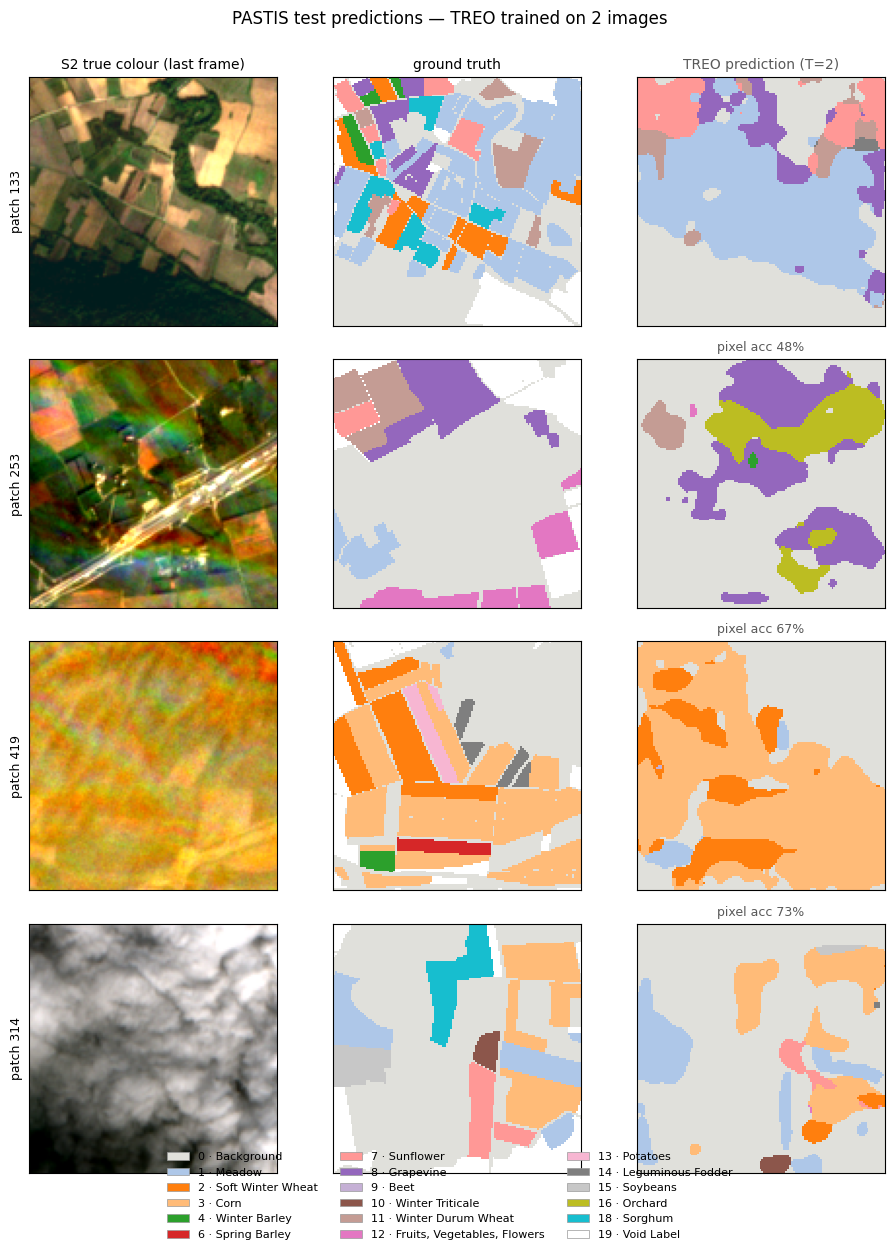

In [6]:
N_SHOW = 4
rng = np.random.default_rng(0)
idxs = rng.choice(len(_raw), size=N_SHOW, replace=False)

fig, axes = plt.subplots(N_SHOW, 3, figsize=(9.5, 3.1 * N_SHOW))
all_masks = []
for r, i in enumerate(idxs):
    pred, tgt = predict_one(model, _loader.dataset, int(i))
    all_masks += [pred, tgt]
    axes[r, 0].imshow(rgb_from_raw(_raw, int(i)))
    axes[r, 1].imshow(tgt,  cmap=CMAP, norm=NORM, interpolation="nearest")
    axes[r, 2].imshow(pred, cmap=CMAP, norm=NORM, interpolation="nearest")
    inter = ((pred == tgt) & (tgt != IGNORE_INDEX)).sum()
    acc = 100 * inter / max((tgt != IGNORE_INDEX).sum(), 1)
    axes[r, 0].set_ylabel(f"patch {int(i)}", fontsize=9)
    axes[r, 2].set_title(f"pixel acc {acc:.0f}%", fontsize=9, color="0.35")
    for c in range(3):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
for c, t in enumerate(["S2 true colour (last frame)", "ground truth", f"TREO prediction (T={TRAIN_T})"]):
    axes[0, c].set_title(t, fontsize=10)
fig.legend(handles=legend_for(all_masks), loc="lower center", ncol=3,
           fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f"PASTIS test predictions — TREO trained on {TRAIN_T} images", fontsize=12)
fig.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

## 5. The experiment — feeding more images at test time

Same weights throughout (**trained on 2 images**), only the test-time input changes.

- **Protocol A (densification)** — rebuild the test set at `multi_temporal=k`. Every k covers
  the whole season; k=2 reproduces the training condition exactly.
- **Protocol B (streaming prefix)** — fix a 12-frame grid and feed the first k frames, i.e. the
  season as it actually unfolds.

In [7]:
K_GRID = [1, 2, 3, 4, 6, 8, 10, 12]

# --- Protocol A: re-sample the whole season at k frames -----------------------------
res_A = {}
for k in K_GRID:
    ld, _ = build_loader(cfg, k)
    res_A[k], _ = evaluate(model, ld)
    print(f"A  k={k:2d}  mIoU {res_A[k]:5.2f}")

# --- Protocol B: fixed 12-frame grid, first k frames --------------------------------
ld12, raw12 = build_loader(cfg, 12)
res_B = {}
for k in K_GRID:
    res_B[k], _ = evaluate(model, ld12, prefix=k)
    print(f"B  k={k:2d}  mIoU {res_B[k]:5.2f}")

A  k= 1  mIoU  5.87
A  k= 2  mIoU 16.14
A  k= 3  mIoU  8.17
A  k= 4  mIoU  5.82
A  k= 6  mIoU  3.04
A  k= 8  mIoU  3.00
A  k=10  mIoU  2.80
A  k=12  mIoU  2.87
B  k= 1  mIoU  6.08
B  k= 2  mIoU 10.07
B  k= 3  mIoU  6.91
B  k= 4  mIoU  4.45
B  k= 6  mIoU  2.98
B  k= 8  mIoU  2.71
B  k=10  mIoU  2.92
B  k=12  mIoU  2.84


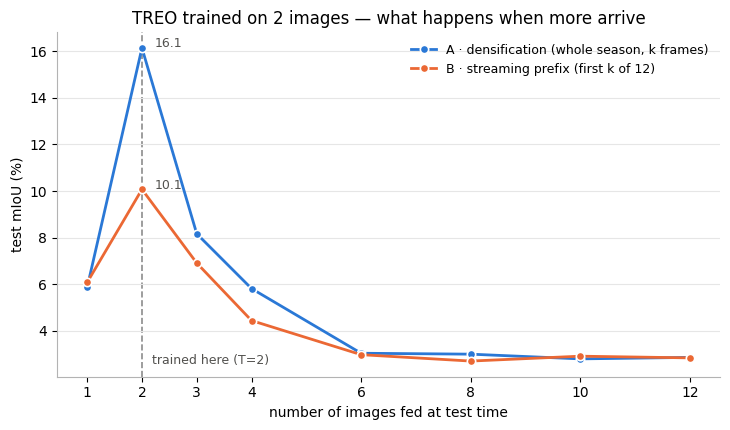


  k |  A densify |  B prefix
----------------------------
  1 |       5.87 |      6.08
  2 |      16.14 |     10.07
  3 |       8.17 |      6.91
  4 |       5.82 |      4.45
  6 |       3.04 |      2.98
  8 |       3.00 |      2.71
 10 |       2.80 |      2.92
 12 |       2.87 |      2.84


In [8]:
# Two series -> legend always present, and both are directly labelled at their last point.
C_A, C_B = "#2a78d6", "#eb6834"          # validated categorical slots 1 and 2
fig, ax = plt.subplots(figsize=(7.4, 4.4))

for res, c, name in ((res_A, C_A, "A · densification (whole season, k frames)"),
                     (res_B, C_B, "B · streaming prefix (first k of 12)")):
    xs = list(res); ys = [res[k] for k in xs]
    ax.plot(xs, ys, color=c, lw=2, marker="o", ms=6, label=name, zorder=3,
            markeredgecolor="white", markeredgewidth=1.2)
    # label each series at its PEAK, not its last point: the tails converge to the
    # same value and their labels would collide.
    j = int(np.argmax(ys))
    ax.annotate(f"{ys[j]:.1f}", (xs[j], ys[j]), textcoords="offset points",
                xytext=(9, 3), fontsize=9, color="#52514e", va="center")

ax.axvline(TRAIN_T, color="0.55", ls="--", lw=1.2, zorder=1)
# sits at the BOTTOM of the axis: the top is where the peak labels live.
ax.annotate(f"trained here (T={TRAIN_T})", (TRAIN_T, ax.get_ylim()[0]),
            textcoords="offset points", xytext=(7, 7), fontsize=9, color="#52514e",
            va="bottom")

ax.set_xlabel("number of images fed at test time")
ax.set_ylabel("test mIoU (%)")
ax.set_title(f"TREO trained on {TRAIN_T} images — what happens when more arrive", fontsize=12)
ax.set_xticks(K_GRID)
ax.grid(axis="y", color="0.9", lw=0.8, zorder=0)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("0.7")
ax.legend(frameon=False, fontsize=9, loc="best")
fig.tight_layout(); plt.show()

# table view (accessibility: never color-alone, and exact values are readable)
print(f"\n{'k':>3} | {'A densify':>10} | {'B prefix':>9}")
print("-" * 28)
for k in K_GRID:
    print(f"{k:>3} | {res_A[k]:>10.2f} | {res_B[k]:>9.2f}")

## 6. Watching one patch as the season unfolds

The same patch decoded after 1, 2, … k acquisitions (Protocol B), so you can see *where* the
extra images change the model's mind.

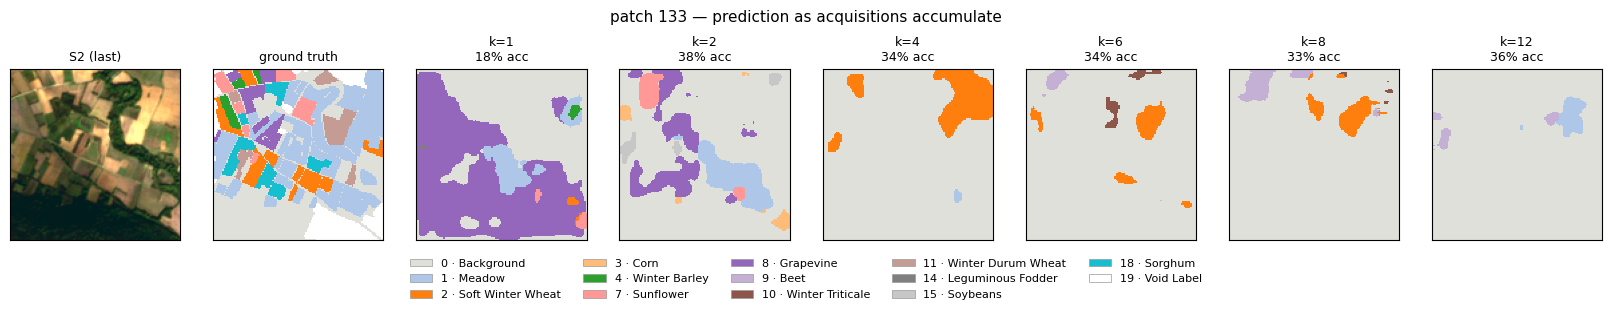

In [9]:
SHOW_K = [1, 2, 4, 6, 8, 12]
pi = int(idxs[0])

fig, axes = plt.subplots(1, len(SHOW_K) + 2, figsize=(2.05 * (len(SHOW_K) + 2), 2.5))
_, tgt = predict_one(model, ld12.dataset, pi, prefix=1)
axes[0].imshow(rgb_from_raw(raw12, pi)); axes[0].set_title("S2 (last)", fontsize=9)
axes[1].imshow(tgt, cmap=CMAP, norm=NORM, interpolation="nearest")
axes[1].set_title("ground truth", fontsize=9)
masks = [tgt]
for a, k in zip(axes[2:], SHOW_K):
    pred, _ = predict_one(model, ld12.dataset, pi, prefix=k)
    masks.append(pred)
    acc = 100 * ((pred == tgt) & (tgt != IGNORE_INDEX)).sum() / max((tgt != IGNORE_INDEX).sum(), 1)
    a.imshow(pred, cmap=CMAP, norm=NORM, interpolation="nearest")
    a.set_title(f"k={k}\n{acc:.0f}% acc", fontsize=9)
for a in axes: a.set_xticks([]); a.set_yticks([])
fig.legend(handles=legend_for(masks), loc="lower center", ncol=5, fontsize=8,
           frameon=False, bbox_to_anchor=(0.5, -0.22))
fig.suptitle(f"patch {pi} — prediction as acquisitions accumulate", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

## 7. Per-class IoU at the best k

Which crops the extra images actually buy you. Sorted, so the classes that move are obvious.

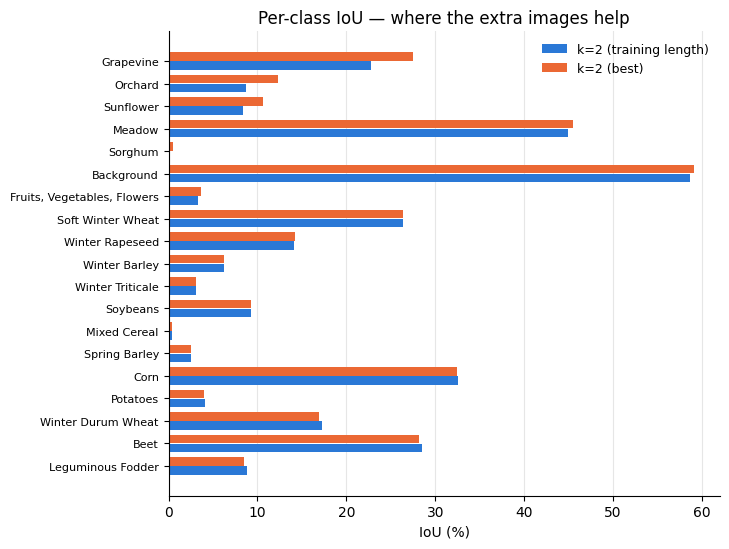

In [10]:
best_k = max(res_A, key=res_A.get)
ld_best, _ = build_loader(cfg, best_k)
_, iou_best = evaluate(model, ld_best)
ld_tr, _    = build_loader(cfg, TRAIN_T)
_, iou_tr   = evaluate(model, ld_tr)

keep = [i for i in range(NUM_CLASSES) if i != IGNORE_INDEX]
order = sorted(keep, key=lambda i: iou_best[i] - iou_tr[i])
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=(7.4, 5.6))
ax.barh(y - 0.2, [iou_tr[i]   for i in order], height=0.38, color="#2a78d6",
        label=f"k={TRAIN_T} (training length)")
ax.barh(y + 0.2, [iou_best[i] for i in order], height=0.38, color="#eb6834",
        label=f"k={best_k} (best)")
ax.set_yticks(y); ax.set_yticklabels([CLASSES[i] for i in order], fontsize=8)
ax.set_xlabel("IoU (%)"); ax.set_title("Per-class IoU — where the extra images help", fontsize=12)
ax.grid(axis="x", color="0.9", lw=0.8, zorder=0); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

## What to take from this

- **Protocol A vs B is the whole story.** If A rises with k but B does not, the model benefits
  from more images *only* when they are spread the way training spread them — it has learned a
  Δt regime, not a general "more evidence is better" rule.
- **The T=2 model is a wide-baseline model.** It was trained on Sep-2018 + Oct-2019. Under
  Protocol B, k=2 hands it two frames one month apart — a Δt it never saw. Judge B against that,
  not against A.
- **A drop as k grows is expected and informative.** TREO's belief norm grows as evidence
  accumulates, so a decoder trained at one k reads later beliefs off-distribution. That is the
  "mIoU cliff": a readout artifact, not proof the extra images are uninformative. To measure the
  information itself, train the decoder at every horizon
  (`task=segmentation_horizon_curve`) and read `mIoU_per_horizon`.
- **If you want a model that genuinely improves as the season unfolds**, train it that way:
  sample a random prefix length per batch so the decoder sees every belief age. That is the
  fix Protocol B is really testing for.

### One caveat on exact numbers

`PastisS2Dates.__getitem__` caps series longer than 50 acquisitions with
`torch.randperm(N)[:50]` — a **fresh random draw on every access**. Tile `t31tfj` has 61
acquisitions (623 of 2433 patches, ~26%), so those patches get a different 50-frame subset each
time you evaluate. Test mIoU therefore jitters by a few hundredths between identical runs — this
notebook measured 16.25 at T=2 where training logged 16.29. Harmless here, but do not read
meaning into differences of that size, and re-run a couple of times if a gap looks marginal.

Point `RUN_DIR` at any other run in the repo root to repeat all of this for the T=4, T=8 or
T=12 model — the notebook reads that run's own config, so nothing else needs changing.